# 08 · Extensions

Work beyond the core plan, from the proposal's scope:

1. **Calibration** of every classifier's probabilities (the proposal promised it), and the **Sortino ratio** in the backtest.
2. **Hidden Markov model regimes** fitted with the Baum–Welch EM algorithm, using filtered (forward-only) probabilities so no day sees the future (`src/fxml/regimes/hmm.py`), compared with the Gaussian mixture and tried as model features (`*_hmm`).
3. A small **Transformer** over the last 20 days, trained like the other networks.
4. **Longer horizons:** volatility and direction over the next 5 and 22 trading days (`src/fxml/models/horizons.py`, `scripts/run_horizons.py`).

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fxml import viz
from fxml.config import load_config
from fxml.validation.metrics import calibration_bins

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
predictions = pd.read_parquet(cfg.paths.reports / "predictions" / "ml.parquet")
curves = pd.read_parquet(cfg.paths.reports / "predictions" / "learning_curves.parquet")
direction = pd.read_csv(tables / "ml_direction.csv")
vol = pd.read_csv(tables / "ml_volatility.csv")
ret = pd.read_csv(tables / "ml_returns.csv")
versus = pd.read_csv(tables / "ml_regime_vs_global.csv")
summary = pd.read_csv(tables / "regimes_summary.csv")
agreement = pd.read_csv(tables / "regimes_agreement.csv", index_col=0)
hmm_selection = pd.read_csv(tables / "regimes_hmm_selection.csv")
hmm_moves = pd.read_csv(tables / "regimes_hmm_transitions.csv")
state = pd.read_parquet(cfg.paths.processed / "market_state.parquet")
strategies = pd.read_csv(tables / "backtest_strategies.csv")
hz_vol = pd.read_csv(tables / "horizons_volatility.csv")
hz_dir = pd.read_csv(tables / "horizons_direction.csv")
pairs = list(cfg.pairs)
test_start = pd.Timestamp(cfg.walk_forward.test_start)
pd.set_option("display.precision", 3)

## 1. Calibration

`ece` is the expected calibration error: the day-weighted gap between the forecast probability and the observed share of up days across ten equal-count bins. `calibration_slope` comes from a logistic regression of the outcome on the forecast's log-odds: 1 is right, below 1 means overconfident. `calibration_slope_se` is its standard error (averaged over pairs): forecasts that barely move, like the historical frequency of up days, leave the slope so poorly pinned down that its value means little.

In [2]:
show = ["baseline_frequency", "logistic_l2", "logistic_l1", "naive_bayes", "knn", "tree",
        "svm_linear", "svm_rbf", "random_forest", "lightgbm", "mlp", "lstm", "transformer"]
average = direction[direction.pair == "average"].set_index("model")
average.loc[[m for m in show if m in average.index], ["roc_auc", "brier", "ece", "calibration_slope", "calibration_slope_se"]].sort_values("ece")

,roc_auc,brier,ece,calibration_slope,calibration_slope_se
model,,,,,
logistic_l1,0.501,0.250,0.023,-0.129,0.440
baseline_frequency,0.490,0.250,0.026,-1.293,1.496
lstm,0.498,0.251,0.028,-0.120,0.337
svm_linear,0.490,0.251,0.029,-1.017,0.654
mlp,0.503,0.250,0.029,0.077,0.330
svm_rbf,0.495,0.251,0.031,-0.207,0.407
logistic_l2,0.503,0.251,0.031,0.096,0.291
random_forest,0.505,0.251,0.032,0.134,0.248
knn,0.502,0.252,0.040,-0.011,0.207


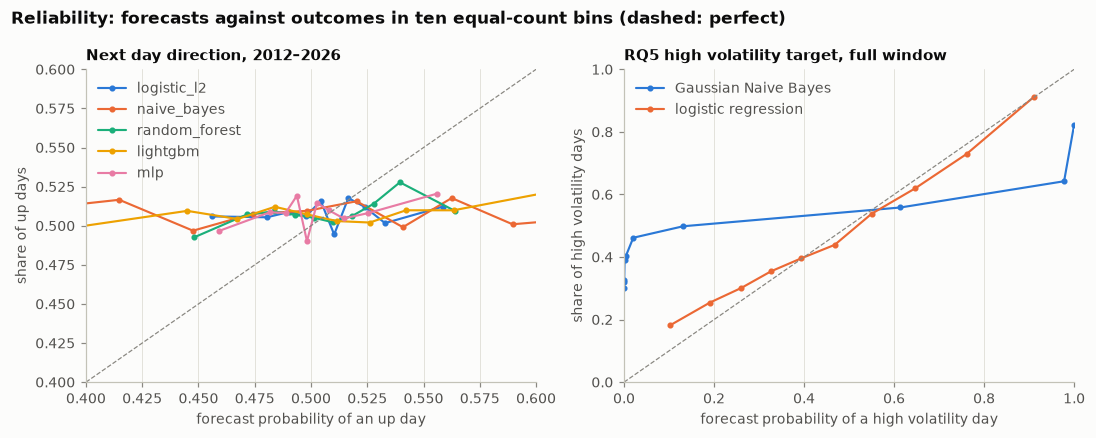

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=False)
ax = axes[0]
models = ["logistic_l2", "naive_bayes", "random_forest", "lightgbm", "mlp"]
for i, model in enumerate(models):
    rows = predictions[(predictions.task == "direction") & (predictions.model == model)]
    table = calibration_bins(rows.actual.to_numpy(), rows.forecast.to_numpy())
    ax.plot(table.mean_forecast, table.frequency, color=viz.CATEGORICAL[i], marker="o", ms=3, label=model)
lims = [0.40, 0.60]
ax.plot(lims, lims, color=viz.INK_MUTED, lw=0.8, ls="--")
ax.set(xlim=lims, ylim=lims, xlabel="forecast probability of an up day", ylabel="share of up days")
ax.set_title("Next day direction, 2012–2026")
ax.legend(loc="upper left")
ax.grid(axis="both")
ax = axes[1]
full = curves[(curves.target == "high_volatility") & (curves["size"] == 0)]
for i, (model, name) in enumerate({"naive_bayes": "Gaussian Naive Bayes", "logistic": "logistic regression"}.items()):
    rows = full[full.model == model]
    table = calibration_bins(rows.actual.to_numpy(), rows.forecast.to_numpy())
    ax.plot(table.mean_forecast, table.frequency, color=viz.CATEGORICAL[i], marker="o", ms=3, label=name)
ax.plot([0, 1], [0, 1], color=viz.INK_MUTED, lw=0.8, ls="--")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="forecast probability of a high volatility day", ylabel="share of high volatility days")
ax.set_title("RQ5 high volatility target, full window")
ax.legend(loc="upper left")
ax.grid(axis="both")
fig.suptitle("Reliability: forecasts against outcomes in ten equal-count bins (dashed: perfect)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "ext_calibration")

In [4]:
pd.read_csv(tables / "ml_learning_curves.csv").pivot_table(index=["target", "size"], columns="model", values="ece")

model                 logistic  naive_bayes
target          size                       
direction       0        0.052        0.166
                21       0.404        0.486
                63       0.364        0.455
                126      0.307        0.404
                252      0.238        0.395
                504      0.165        0.375
                1008     0.106        0.289
high_volatility 0        0.031        0.311
                21       0.356        0.408
                63       0.306        0.361
                126      0.256        0.332
                252      0.178        0.329
                504      0.113        0.337
                1008     0.067        0.327

### Sortino ratio

Like the Sharpe ratio, but only losing days count as risk. Equal-risk portfolio, net of costs.

In [5]:
portfolio = strategies[strategies.pair == "portfolio"].set_index(["signal", "sizing"])
rows = [(s, "unit") for s in ["long", "carry", "momentum", "logistic_l2", "random_forest", "lightgbm", "mlp"]]
rows += [(s, "vt_lightgbm") for s in ["long", "carry"]]
portfolio.loc[rows, ["ann_return", "ann_vol", "sharpe", "sortino", "max_drawdown"]]

,,ann_return,ann_vol,sharpe,sortino,max_drawdown
signal,sizing,,,,,
long,unit,0.005,0.032,0.153,0.206,-0.131
carry,unit,0.011,0.045,0.244,0.335,-0.115
momentum,unit,-0.001,0.052,-0.022,-0.031,-0.153
logistic_l2,unit,-0.009,0.043,-0.214,-0.301,-0.251
random_forest,unit,-0.006,0.040,-0.155,-0.217,-0.225
lightgbm,unit,-0.016,0.040,-0.391,-0.531,-0.288
mlp,unit,-0.020,0.039,-0.515,-0.691,-0.392
long,vt_lightgbm,0.007,0.032,0.229,0.312,-0.127
carry,vt_lightgbm,0.014,0.052,0.265,0.368,-0.173


## 2. Hidden Markov model regimes

Same market state and number of regimes as the Gaussian mixture, refitted every January, with filtered probabilities only.

In [6]:
hmm_selection.assign(best=lambda d: d.bic == d.bic.min())

,k,bic,best
0,2,13335.840,False
1,3,11312.440,False
2,4,10230.171,False
3,5,9478.733,False
4,6,8740.294,True


In [7]:
# Estimated transition matrix (full sample fit): the chance of each regime tomorrow given today's
hmm_moves.pivot(index="from", columns="to", values="probability")

to,0,1
from,,
0,0.991,0.009
1,0.008,0.992


In [8]:
cols = ["share_of_days", "spells", "mean_spell_days", "median_spell_days", "stay_probability",
        "next_day_vol_pct", "stress_share", "stress_capture"]
summary[summary.method.isin(["gmm", "hmm"]) & (summary.labels == "walk_forward")].set_index(["method", "regime"])[cols]

share_of_days  spells  mean_spell_days  median_spell_days  \
method regime                                                              
gmm    0               0.753      86           33.581               12.0   
       1               0.247      86           11.000                5.0   
hmm    0               0.639      53           46.208               26.0   
       1               0.361      53           26.132               16.0   

               stay_probability  next_day_vol_pct  stress_share  \
method regime                                                     
gmm    0                  0.970             8.679         0.080   
       1                  0.910            10.872         0.198   
hmm    0                  0.978             8.693         0.091   
       1                  0.962            10.206         0.141   

               stress_capture  
method regime                  
gmm    0                0.554  
       1                0.446  
hmm    0                0.535  
       1                0.465

In [9]:
agreement.round(2)

,kmeans,ward,gmm,dbscan,hmm
kmeans,1.00,0.60,0.25,0.05,0.13
ward,0.60,1.00,0.20,0.02,0.11
gmm,0.25,0.20,1.00,0.14,0.38
dbscan,0.05,0.02,0.14,1.00,0.08
hmm,0.13,0.11,0.38,0.08,1.00


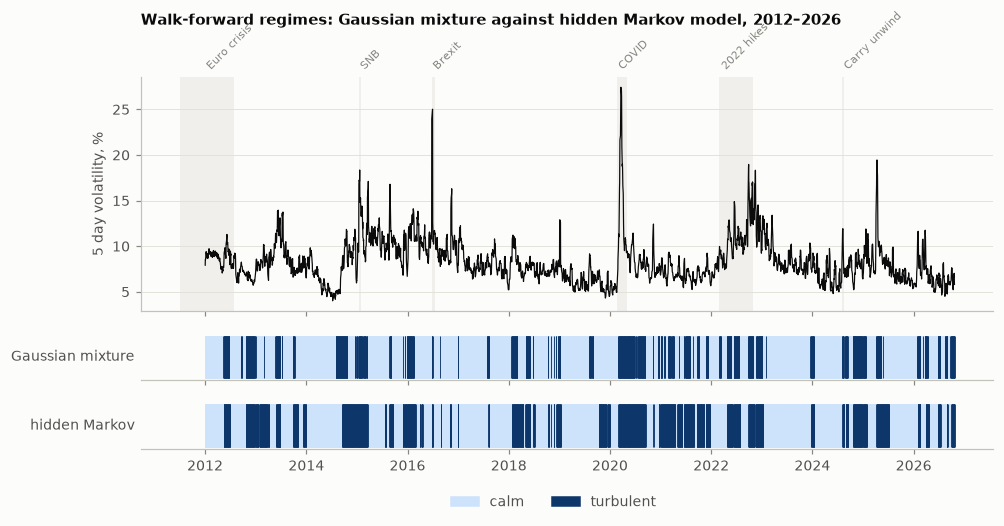

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 4.4), sharex=True,
                         gridspec_kw={"height_ratios": [3, 0.6, 0.6], "hspace": 0.2})
test = state[state.index >= test_start]
ax = axes[0]
viz.shade_stress(ax, label=True, since=test_start)
ax.plot(test.index, 100 * np.sqrt(np.exp(test.vol_short) * 252), color=viz.INK, lw=0.8)
ax.set_ylabel("5 day volatility, %")
ax.set_title("Walk-forward regimes: Gaussian mixture against hidden Markov model, 2012–2026", pad=34)
colors = [viz.SEQUENTIAL_BLUE[0], viz.SEQUENTIAL_BLUE[6]]
for ax, (column, name) in zip(axes[1:], [("regime_gmm", "Gaussian mixture"), ("regime_hmm", "hidden Markov")]):
    labels = test[column].dropna()
    for regime, color in enumerate(colors):
        days = labels.index[labels == regime]
        ax.vlines(days, 0, 1, color=color, lw=0.6)
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", color=viz.INK_SECONDARY)
    ax.grid(False)
    ax.spines["left"].set_visible(False)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors]
fig.legend(handles, ["calm", "turbulent"], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
viz.save(fig, "ext_hmm_timeline")

### Do HMM regimes help the forecasts?

Diebold–Mariano tests of each `_hmm` variant (HMM probabilities as features) against its global model, next to the mixture variants (`_regime`) from Phase 4.

In [11]:
counts = versus[versus.pair == "average"].drop(columns=["pair", "dm_vs_global", "dm_p_vs_global"])
counts[counts.model.str.endswith(("_hmm", "_regime"))].sort_values(["task", "global_model", "model"])

,task,model,global_model,pairs_significantly_better,pairs_significantly_worse
127,direction,lightgbm_hmm,lightgbm,0.0,0.0
128,direction,lightgbm_regime,lightgbm,0.0,0.0
130,direction,logistic_l2_hmm,logistic_l2,3.0,0.0
131,direction,logistic_l2_regime,logistic_l2,0.0,0.0
133,returns,lightgbm_hmm,lightgbm,0.0,0.0
134,returns,lightgbm_regime,lightgbm,0.0,0.0
136,returns,ridge_hmm,ridge,0.0,0.0
137,returns,ridge_regime,ridge,1.0,0.0
139,volatility,lightgbm_hmm,lightgbm,0.0,0.0
140,volatility,lightgbm_regime,lightgbm,0.0,0.0


In [12]:
show = ["baseline_har", "ridge", "ridge_regime", "ridge_hmm", "lightgbm", "lightgbm_regime", "lightgbm_hmm"]
vol[vol.pair == "average"].set_index("model").loc[show, ["qlike", "mz_r2", "pairs_significantly_better"]]

,qlike,mz_r2,pairs_significantly_better
model,,,
baseline_har,0.157,0.546,0.0
ridge,0.156,0.559,3.0
ridge_regime,0.156,0.559,3.0
ridge_hmm,0.155,0.559,3.0
lightgbm,0.147,0.574,5.0
lightgbm_regime,0.149,0.572,5.0
lightgbm_hmm,0.148,0.573,5.0


## 3. Transformer

In [13]:
show = ["baseline_har", "lightgbm", "mlp", "lstm", "transformer"]
table = pd.concat({
    "volatility qlike": vol[vol.pair == "average"].set_index("model").loc[show[0:], "qlike"],
    "direction auc": direction[direction.pair == "average"].set_index("model").reindex(show)["roc_auc"],
    "returns r2_oos": ret[ret.pair == "average"].set_index("model").reindex(show)["r2_oos"],
}, axis=1)
table

,volatility qlike,direction auc,returns r2_oos
model,,,
baseline_har,0.157,NaN,NaN
lightgbm,0.147,0.504,-0.021
mlp,0.151,0.503,-0.004
lstm,0.159,0.498,-0.006
transformer,0.161,0.501,-0.017


## 4. Longer horizons

Volatility: the average daily variance over the next *h* days. Direction: whether the summed return over the next *h* days is positive. Diebold–Mariano tests allow for the overlap of consecutive forecasts; `pairs_significantly_better` counts pairs that beat HAR-RV (volatility) or the frequency of up periods (direction).

In [14]:
one_day = vol[vol.pair == "average"].set_index("model").rename(index=lambda m: m.removeprefix("baseline_"))
rows = []
for model in ["naive", "ewma", "garch", "har", "ridge", "lightgbm"]:
    rows.append({"model": model, "horizon": 1, "qlike": one_day.loc[model, "qlike"],
                 "pairs_significantly_better": one_day.loc[model, "pairs_significantly_better"]})
longer = hz_vol[hz_vol.pair == "average"][["model", "horizon", "qlike", "pairs_significantly_better"]]
horizon_table = pd.concat([pd.DataFrame(rows), longer], ignore_index=True)
har = horizon_table[horizon_table.model == "har"].set_index("horizon")["qlike"]
horizon_table["gain_vs_har_pct"] = 100 * (1 - horizon_table.qlike / horizon_table.horizon.map(har))
horizon_table.pivot(index="model", columns="horizon", values=["qlike", "gain_vs_har_pct", "pairs_significantly_better"])

qlike               gain_vs_har_pct                  \
horizon      1      5      22              1       5       22   
model                                                           
ewma      0.213  0.161  0.179         -36.100 -47.994 -54.243   
garch     0.193  0.136  0.131         -23.283 -24.647 -13.077   
har       0.157  0.109  0.116           0.000   0.000   0.000   
lightgbm  0.147  0.116  0.145           6.098  -6.289 -25.046   
naive     0.212  0.130  0.145         -35.203 -19.734 -24.650   
ridge     0.156  0.117  0.135           0.645  -7.473 -16.449   

         pairs_significantly_better            
horizon                          1    5    22  
model                                          
ewma                            0.0  0.0  0.0  
garch                           0.0  0.0  0.0  
har                             0.0  0.0  0.0  
lightgbm                        5.0  0.0  0.0  
naive                           0.0  0.0  0.0  
ridge                           3.0  0.0  0.0

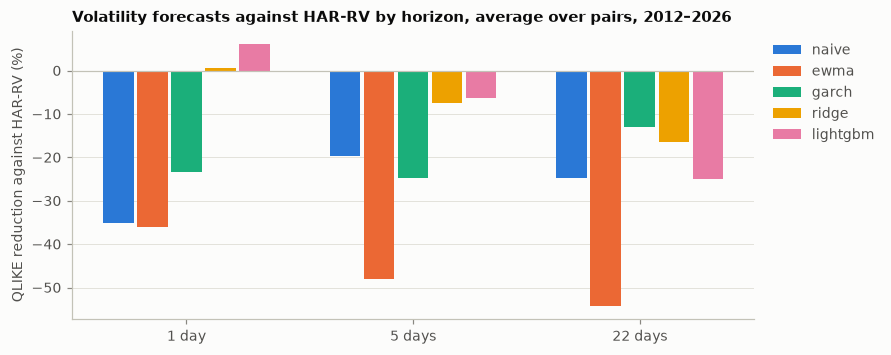

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.4))
models = ["naive", "ewma", "garch", "ridge", "lightgbm"]
x = np.arange(3)
width = 0.15
for i, model in enumerate(models):
    rows = horizon_table[horizon_table.model == model].sort_values("horizon")
    ax.bar(x + (i - 2) * width, rows.gain_vs_har_pct, width=width * 0.9, color=viz.CATEGORICAL[i], label=model)
ax.axhline(0, color=viz.BASELINE, lw=0.8)
ax.set_xticks(x, ["1 day", "5 days", "22 days"])
ax.set_ylabel("QLIKE reduction against HAR-RV (%)")
ax.set_title("Volatility forecasts against HAR-RV by horizon, average over pairs, 2012–2026")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
viz.save(fig, "ext_horizons_volatility")

In [16]:
dir_one = direction[direction.pair == "average"].set_index("model").rename(index=lambda m: m.removeprefix("baseline_"))
rows = [{"model": m, "horizon": 1, "accuracy": dir_one.loc[m, "accuracy"], "roc_auc": dir_one.loc[m, "roc_auc"],
         "brier": dir_one.loc[m, "brier"]} for m in ["frequency", "logistic_l2", "lightgbm"]]
longer = hz_dir[hz_dir.pair == "average"][["model", "horizon", "accuracy", "roc_auc", "brier", "pairs_significantly_better"]]
pd.concat([pd.DataFrame(rows), longer], ignore_index=True).pivot(index="model", columns="horizon",
                                                                 values=["accuracy", "roc_auc", "brier"])

accuracy               roc_auc                brier              
horizon           1      5      22      1      5      22     1      5      22
model                                                                        
frequency      0.499  0.493  0.473   0.490  0.474  0.440  0.250  0.251  0.253
lightgbm       0.502  0.503  0.495   0.504  0.505  0.498  0.253  0.258  0.278
logistic_l2    0.503  0.497  0.499   0.503  0.496  0.498  0.251  0.252  0.260

In [17]:
hz_dir[hz_dir.pair == "average"].set_index(["horizon", "model"])[["pairs_significantly_better"]]

pairs_significantly_better
horizon model                                  
5       frequency                           0.0
        lightgbm                            0.0
        logistic_l2                         0.0
22      frequency                           0.0
        lightgbm                            0.0
        logistic_l2                         0.0